# Testing drift bursts against controlled null models

Drift and volatility increase as time approaches a chosen burst location:

$$
\mu_t=\frac{a(t)}{|t-\tau|^{\alpha}},\qquad
\sigma_t=\frac{b(t)}{|t-\tau|^{\beta}},\qquad \tau=\frac12.
$$

Here, $t$ is normalized time; $\tau=\tfrac12$ is the burst location; $\mu_t$ is drift; $\sigma_t$ is volatility. $a(t)$ and $b(t)$ set their signed and positive scales; $\alpha$ and $\beta$ control how sharply they rise near $\tau.$

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]

from RiskLabAI.data.synthetic_data import drift_volatility_burst

FIGURES = ROOT / "outputs" / "figures" / "02_synthetic_financial_environments"
TABLES = ROOT / "outputs" / "tables" / "02_synthetic_financial_environments"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {
    "background": "#111827",
    "axes": "#111827",
    "text": "#E5E7EB",
    "cyan": "#38BDF8",
    "amber": "#FBBF24",
    "green": "#34D399",
    "rose": "#FB7185",
    "violet": "#C084FC",
    "grid": "#374151",
}
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11.5,
    "figure.facecolor": palette["background"],
    "axes.facecolor": palette["axes"],
    "axes.edgecolor": palette["text"],
    "axes.labelcolor": palette["text"],
    "axes.titlecolor": palette["text"],
    "xtick.color": palette["text"],
    "ytick.color": palette["text"],
    "text.color": palette["text"],
    "grid.color": palette["grid"],
    "grid.linestyle": ":",
    "legend.facecolor": palette["axes"],
    "legend.edgecolor": palette["grid"],
    "savefig.facecolor": palette["background"],
})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Regularized Burst Profile

A positive distance floor prevents the drift and volatility profiles from becoming infinite at the burst location:

$$
d_{\delta}(t)=\max\{|t-\tfrac12|,\delta\},\qquad
\mu_t=\frac{a(t)}{d_{\delta}(t)^{\alpha}},\qquad
\sigma_t=\frac{b(t)}{d_{\delta}(t)^{\beta}},\qquad t\neq\tfrac12.
$$

Here, $d_\delta(t)$ is the floored distance to $\tfrac12$; $\delta>0$ is the smallest allowed distance; $t$ is normalized time. $\mu_t$ and $\sigma_t$ are drift and volatility; $a(t),b(t)$ are scale functions; $\alpha,\beta$ are burst exponents.

In [2]:
observation_count = 501
time = np.linspace(0.0, 1.0, observation_count)
midpoint = observation_count // 2
a_before = 0.025
a_after = -0.018
b_before = 0.12
b_after = 0.18
alpha = 0.35
beta = 0.22
filter_width = 0.06

drift, volatility = drift_volatility_burst(
    bubble_length=observation_count,
    a_before=a_before,
    a_after=a_after,
    b_before=b_before,
    b_after=b_after,
    alpha=alpha,
    beta=beta,
    explosion_filter_width=filter_width,
)

drift_burst_parameters = pd.DataFrame({
    "Quantity": [
        "Observations",
        "Pre-burst drift scale",
        "Post-burst drift scale",
        "Pre-burst volatility scale",
        "Post-burst volatility scale",
        "Drift exponent",
        "Volatility exponent",
        "Regularization width",
    ],
    "Value": [observation_count, a_before, a_after, b_before, b_after, alpha, beta, filter_width],
})
save_table(drift_burst_parameters, "drift_burst_parameters", "Parameters for the regularized drift and volatility burst.", "tab:drift-burst-parameters", fit=False)
display(drift_burst_parameters)

,Quantity,Value
0,Observations,501
1,Pre-burst drift scale,0.025
2,Post-burst drift scale,-0.018
3,Pre-burst volatility scale,0.120
4,Post-burst volatility scale,0.180
5,Drift exponent,0.350
6,Volatility exponent,0.220
7,Regularization width,0.060


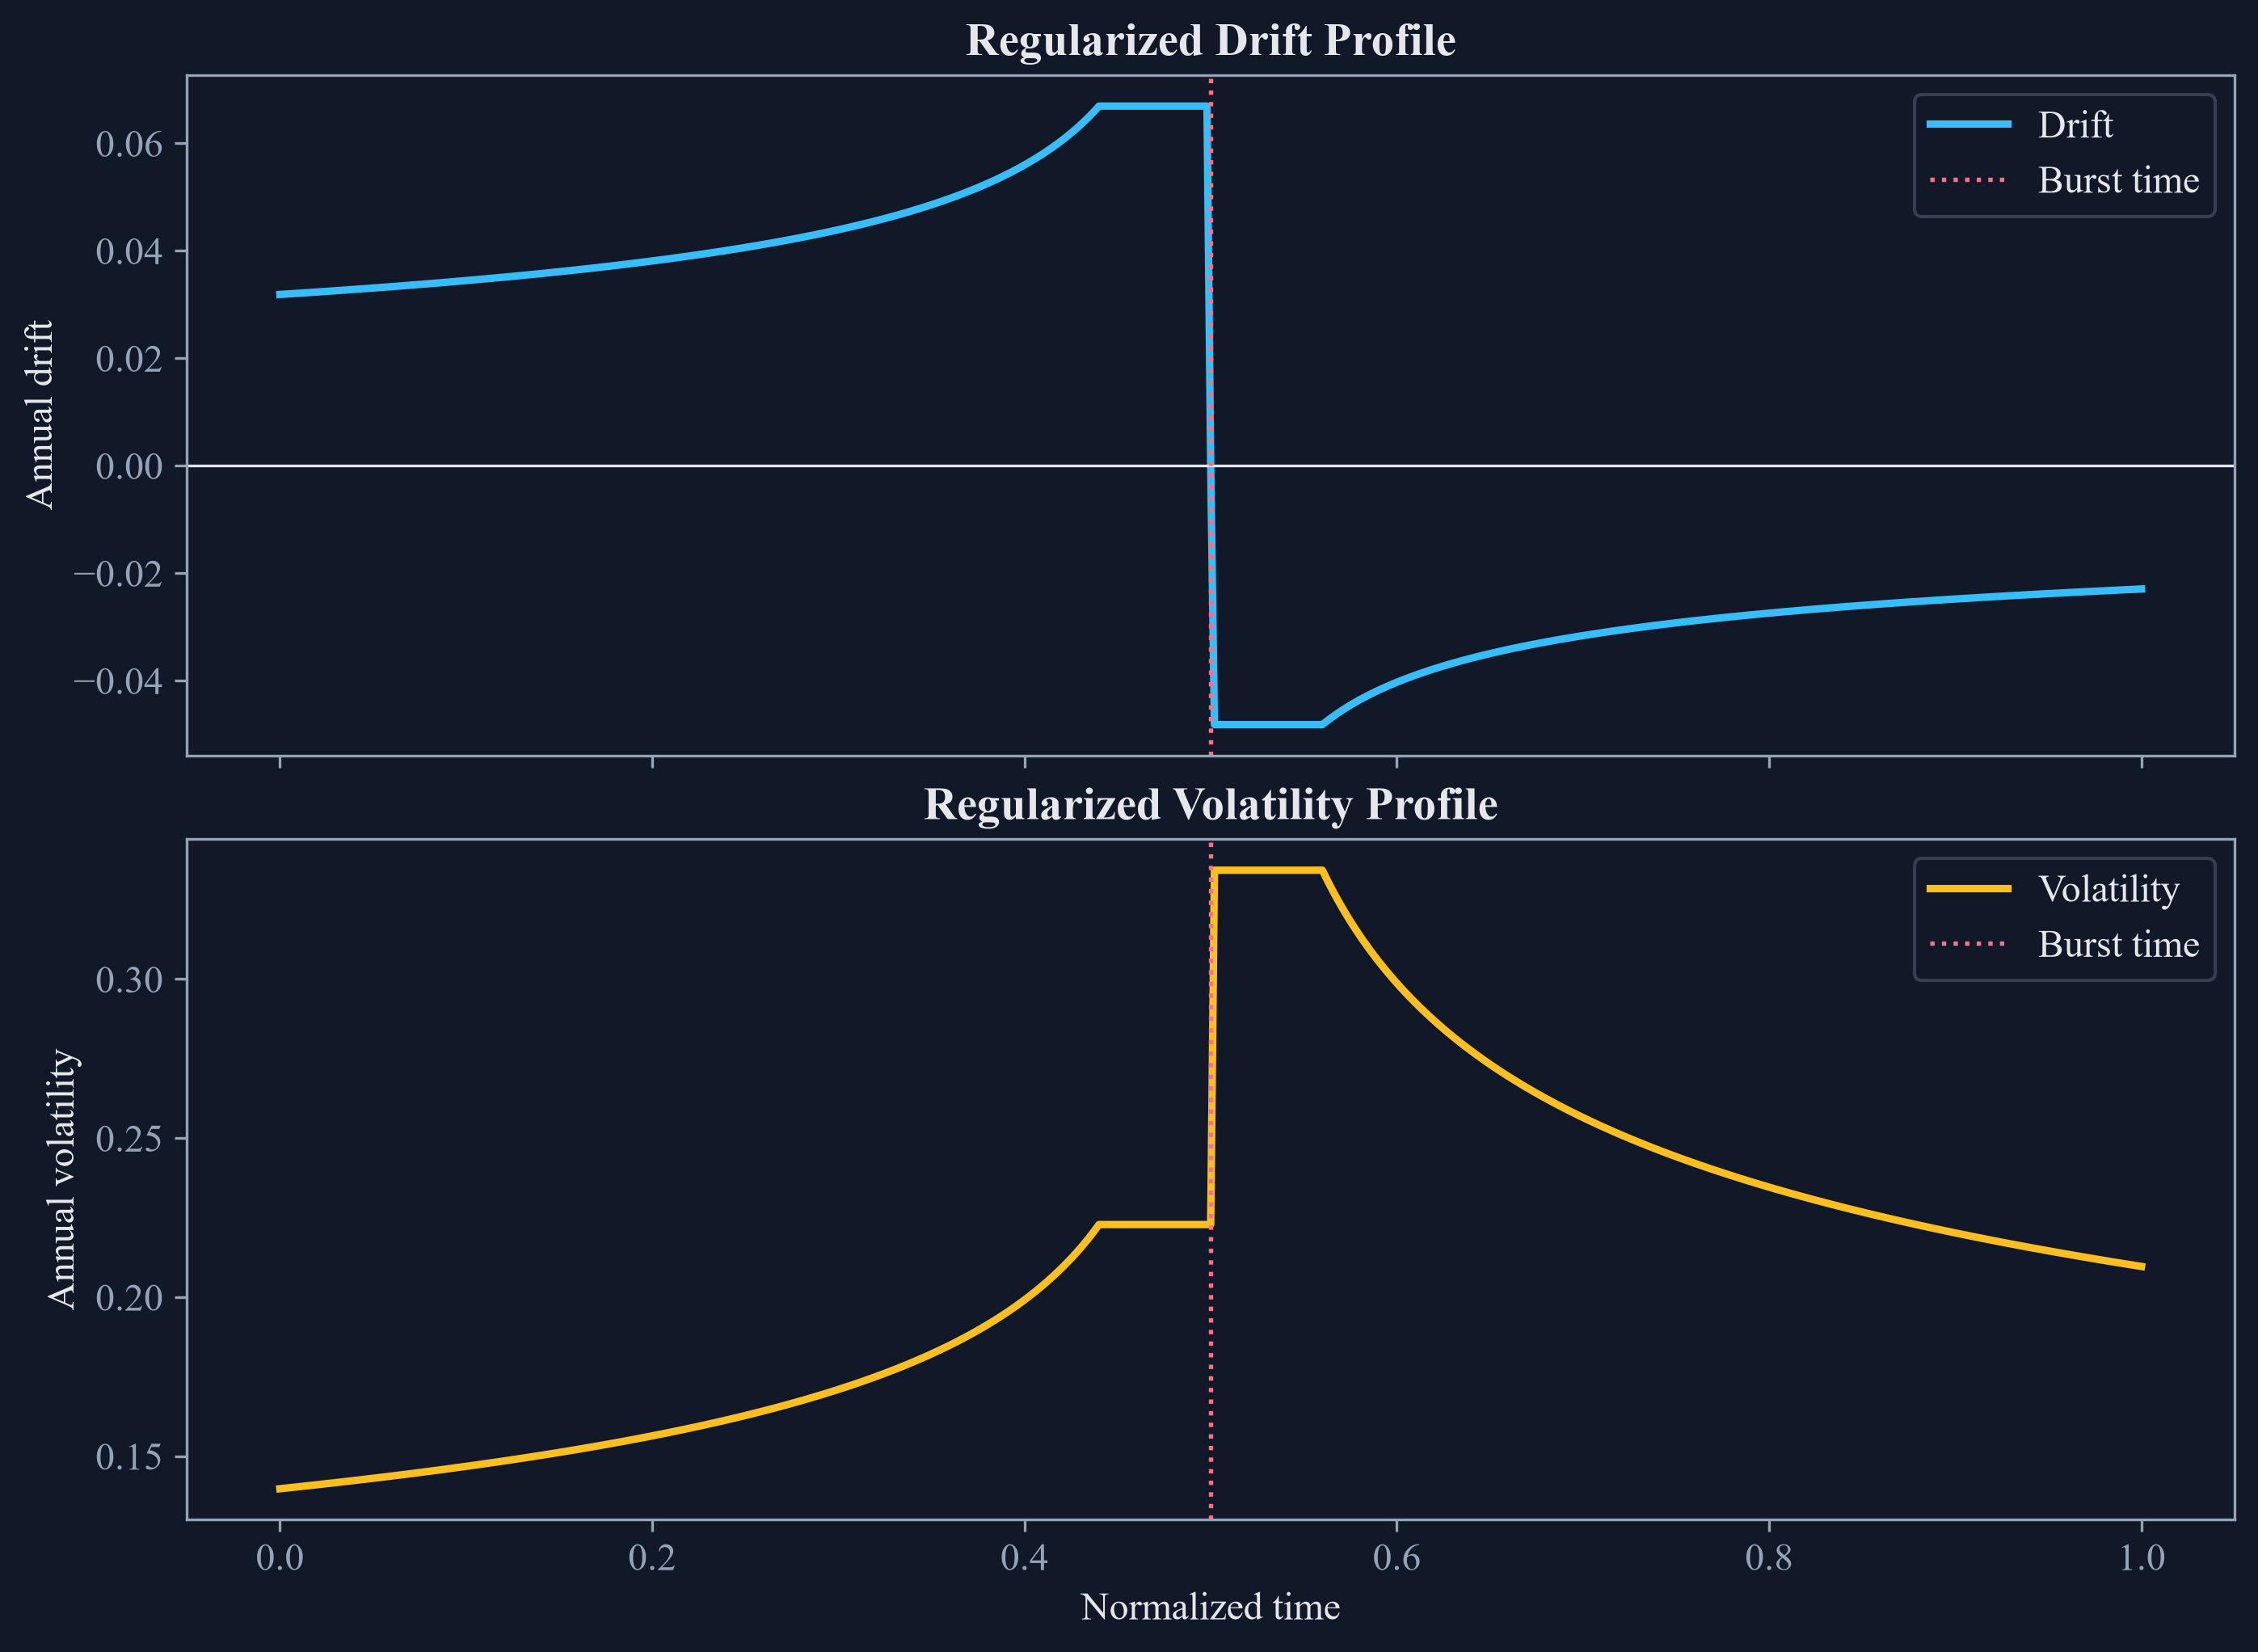

In [3]:
figure, axes = plt.subplots(2, 1, figsize=(9.2, 6.7), sharex=True, constrained_layout=True)
axes[0].plot(time, drift, color=palette["cyan"], linewidth=2.2, label="Drift")
axes[0].axhline(0.0, color=palette["text"], linewidth=0.8)
axes[0].axvline(0.5, color=palette["rose"], linewidth=1.3, linestyle=":", label="Burst time")
axes[0].set_ylabel("Annual drift")
axes[0].set_title("Regularized Drift Profile")
axes[0].legend()
axes[1].plot(time, volatility, color=palette["amber"], linewidth=2.2, label="Volatility")
axes[1].axvline(0.5, color=palette["rose"], linewidth=1.3, linestyle=":", label="Burst time")
axes[1].set_xlabel("Normalized time")
axes[1].set_ylabel("Annual volatility")
axes[1].set_title("Regularized Volatility Profile")
axes[1].legend()
figure.savefig(FIGURES / "drift_burst_profiles.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "drift_burst_profiles.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "drift_burst_profiles.png")))
plt.close(figure)

## Comparing paired null and alternative paths

The two return paths share the same shocks, so their difference isolates the time-varying drift and volatility:

$$
R_t^{(0)}=\mu_0\Delta+\sigma_0\sqrt{\Delta}\,Z_t,\qquad
R_t^{(1)}=\mu_t\Delta+\sigma_t\sqrt{\Delta}\,Z_t,
\qquad Z_t\overset{\mathrm{iid}}{\sim}\mathcal N(0,1).
$$

Here, $R_t^{(0)}$ is the constant-parameter return; $R_t^{(1)}$ is the burst return; $\mu_0,\sigma_0$ are fixed drift and volatility. $\mu_t,\sigma_t$ vary through time; $\Delta$ is the time step; $Z_t$ is an independent standard-normal shock; iid means independent and identically distributed.

In [4]:
time_step = 1.0 / 252.0
random_generator = np.random.default_rng(20260929)
innovations = random_generator.standard_normal(observation_count)
null_drift = 0.0
null_volatility = float(np.median(volatility))
null_returns = null_drift * time_step + null_volatility * np.sqrt(time_step) * innovations
alternative_returns = drift * time_step + volatility * np.sqrt(time_step) * innovations
null_prices = 100.0 * np.exp(np.cumsum(null_returns))
alternative_prices = 100.0 * np.exp(np.cumsum(alternative_returns))

def maximum_drawdown(prices):
    running_peak = np.maximum.accumulate(prices)
    return float(np.min(prices / running_peak - 1.0))

controlled_alternative_summary = pd.DataFrame({
    "Environment": ["Null", "Burst alternative"],
    "Terminal price": [null_prices[-1], alternative_prices[-1]],
    "Annualized mean return": [null_returns.mean() / time_step, alternative_returns.mean() / time_step],
    "Annualized volatility": [null_returns.std(ddof=1) / np.sqrt(time_step), alternative_returns.std(ddof=1) / np.sqrt(time_step)],
    "Maximum drawdown": [maximum_drawdown(null_prices), maximum_drawdown(alternative_prices)],
    "One-percent return quantile": [np.quantile(null_returns, 0.01), np.quantile(alternative_returns, 0.01)],
})
save_table(controlled_alternative_summary, "controlled_alternative_summary", "Paired null and burst-alternative outcomes under common innovations.", "tab:controlled-alternative-summary")
display(controlled_alternative_summary.round(6))

,Environment,Terminal price,Annualized mean return,Annualized volatility,Maximum drawdown,One-percent return quantile
0,Null,54.298194,-0.307168,0.210407,-0.467856,-0.030930
1,Burst alternative,64.481896,-0.220707,0.218168,-0.378051,-0.032023


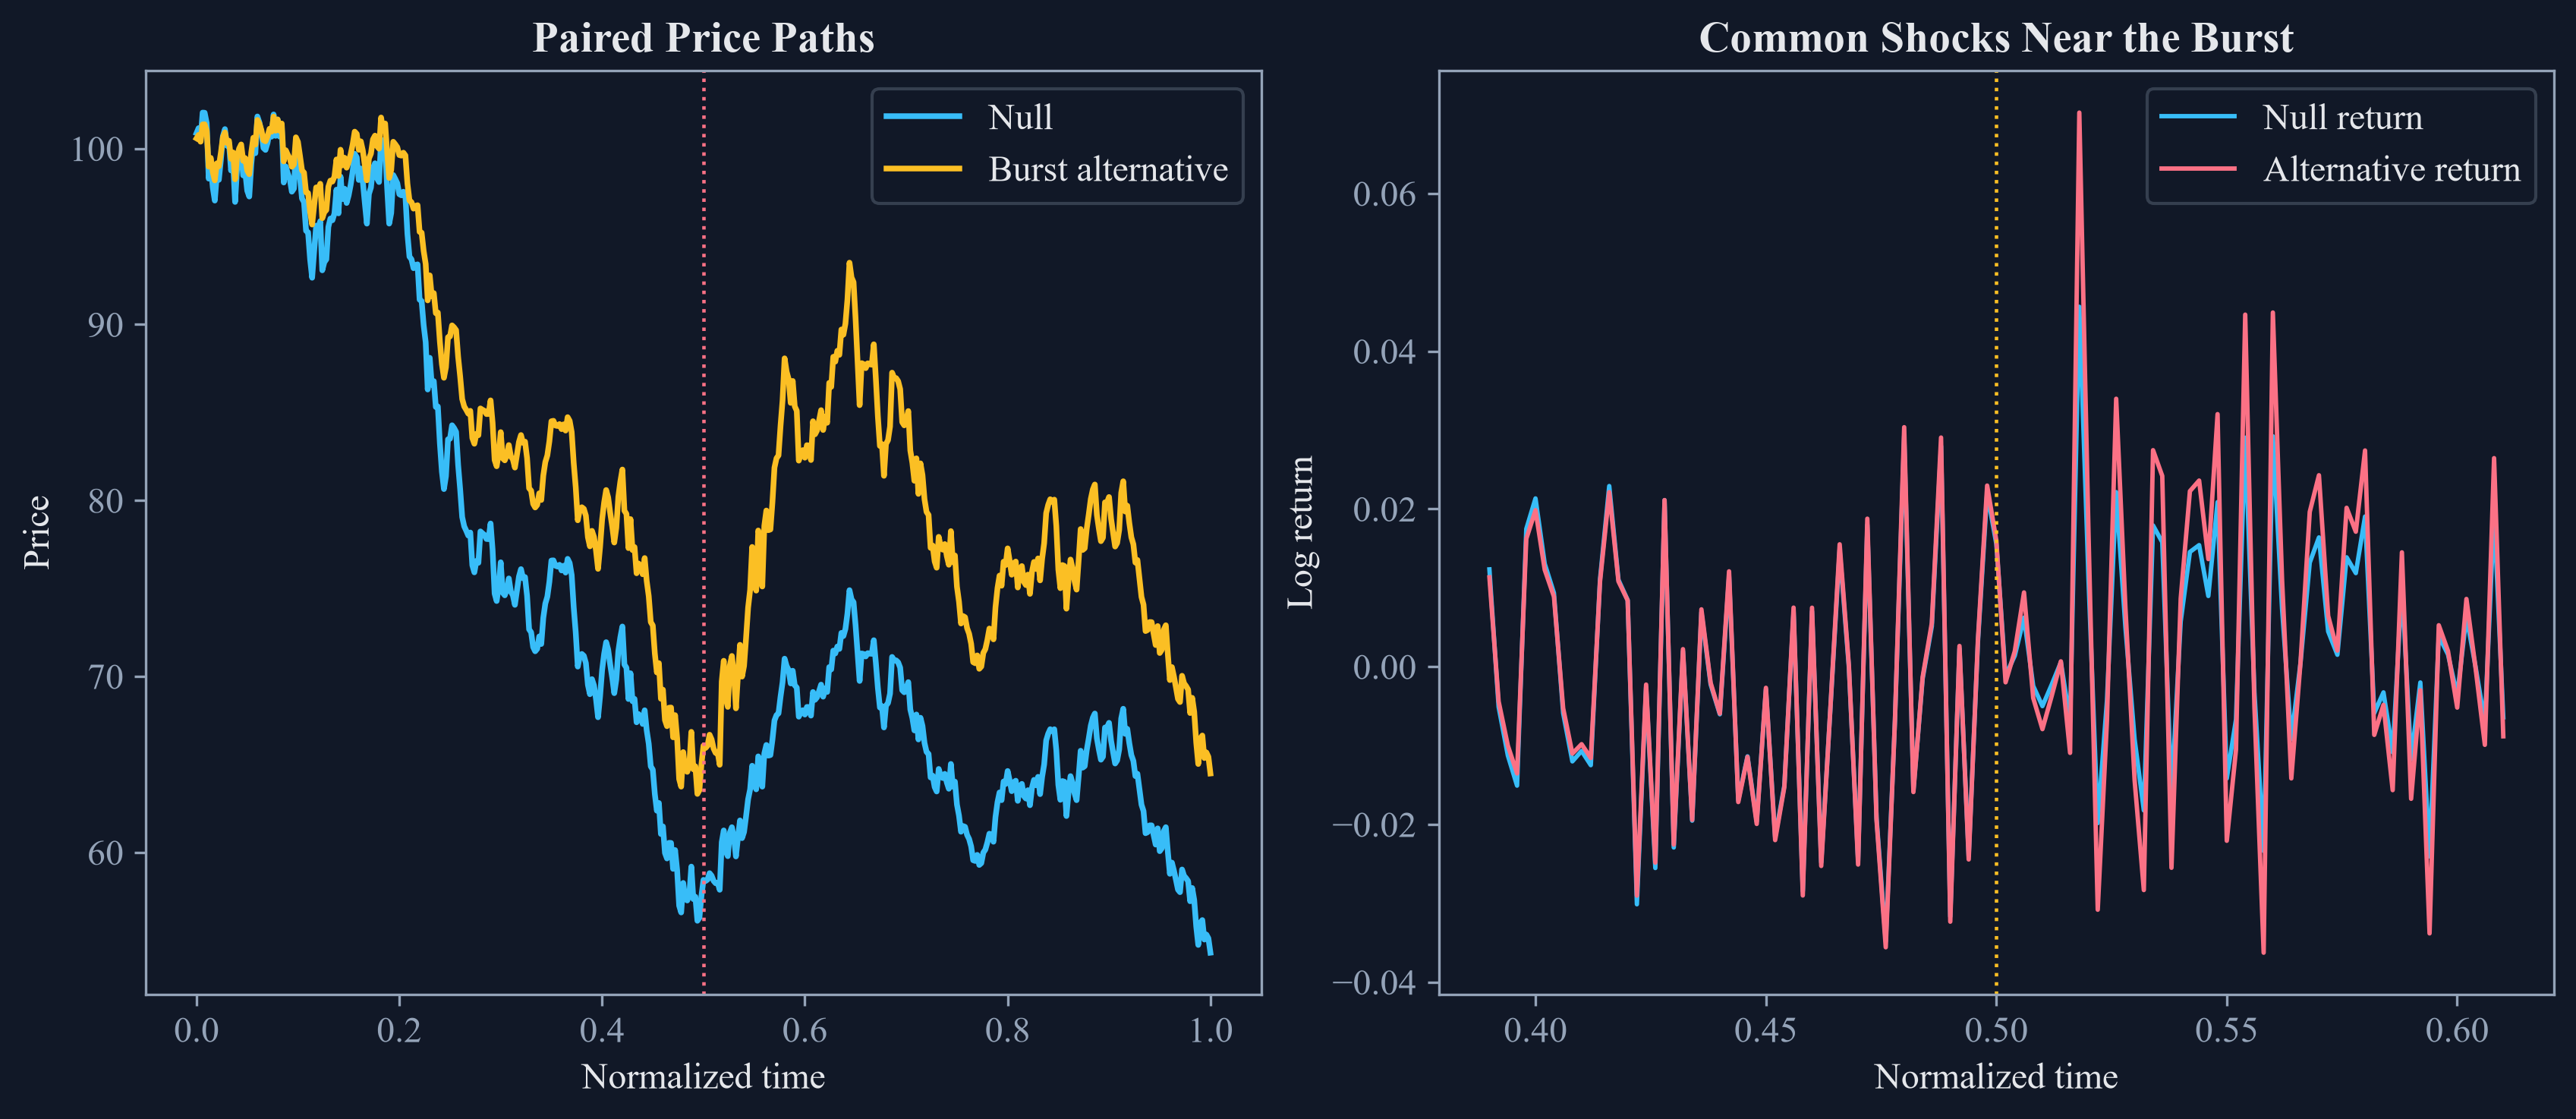

In [5]:
local_window = slice(midpoint - 55, midpoint + 56)
figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), constrained_layout=True)
axes[0].plot(time, null_prices, color=palette["cyan"], linewidth=1.8, label="Null")
axes[0].plot(time, alternative_prices, color=palette["amber"], linewidth=1.8, label="Burst alternative")
axes[0].axvline(0.5, color=palette["rose"], linewidth=1.1, linestyle=":")
axes[0].set_xlabel("Normalized time")
axes[0].set_ylabel("Price")
axes[0].set_title("Paired Price Paths")
axes[0].legend()
axes[1].plot(time[local_window], null_returns[local_window], color=palette["cyan"], linewidth=1.4, label="Null return")
axes[1].plot(time[local_window], alternative_returns[local_window], color=palette["rose"], linewidth=1.4, label="Alternative return")
axes[1].axvline(0.5, color=palette["amber"], linewidth=1.1, linestyle=":")
axes[1].set_xlabel("Normalized time")
axes[1].set_ylabel("Log return")
axes[1].set_title("Common Shocks Near the Burst")
axes[1].legend()
figure.savefig(FIGURES / "paired_null_alternative.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "paired_null_alternative.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "paired_null_alternative.png")))
plt.close(figure)

## Tests

In [6]:
repeated_innovations = np.random.default_rng(20260929).standard_normal(observation_count)
expected_pre_drift = a_before / filter_width**alpha
expected_post_drift = a_after / filter_width**alpha
expected_pre_volatility = b_before / filter_width**beta
expected_post_volatility = b_after / filter_width**beta
recovered_null_innovations = (null_returns - null_drift * time_step) / (null_volatility * np.sqrt(time_step))
recovered_alternative_innovations = (alternative_returns - drift * time_step) / (volatility * np.sqrt(time_step))
assert drift.shape == volatility.shape == (observation_count,)
assert np.isclose(time[midpoint], 0.5)
assert drift[midpoint] == 0.0
assert volatility[midpoint] == volatility[midpoint - 1]
assert np.isclose(drift[midpoint - 1], expected_pre_drift)
assert np.isclose(drift[midpoint + 1], expected_post_drift)
assert np.isclose(volatility[midpoint - 1], expected_pre_volatility)
assert np.isclose(volatility[midpoint + 1], expected_post_volatility)
assert np.array_equal(innovations, repeated_innovations)
assert np.allclose(recovered_null_innovations, innovations)
assert np.allclose(recovered_alternative_innovations, innovations)
assert np.all(np.isfinite(null_prices)) and np.all(null_prices > 0.0)
assert np.all(np.isfinite(alternative_prices)) and np.all(alternative_prices > 0.0)
assert not np.array_equal(null_returns, alternative_returns)
assert len(controlled_alternative_summary) == 2